In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    VotingClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

sns.set_style("whitegrid")

**Task 1: Load and Explore the Dataset**

In [3]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

In [4]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [ ]:
#number of observations and number of features
print("(observations, features)")
print(X.shape)

#feature names
print("\nfeature names:")
print(data.feature_names)

#data types
print("\ndata types:")
print(X.dtypes)

#missing values?
print("\nmissing values?")
print(X.isnull().values.any())

(observations, features)
(569, 30)

feature names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']

data types:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               floa

*Questions*

1. 569
2. 30
3. Numerical
4. No
5. Balanced

**Task 2: Understand the Target Variable**

In [22]:
print(data.target_names)
y.value_counts()

['malignant' 'benign']


target
1    357
0    212
Name: count, dtype: int64

*Questions*

1. Malignant
2. Benign
3. Benign
4. To make sure overfitting doesn't happen

**Task 3: Split the Data**

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [26]:
#number of training observations
print("number of training observations, #features:")
print(X_train.shape)

#number of test observations
print("\nnumber of test observations, #features:")
print(X_test.shape)

number of training observations, #features:
(455, 30)

number of test observations, #features:
(114, 30)


*Questions*

1. 455
2. 114
3. 30

We use stratify = y to make sure we get a number of cases from both classes that is proportional to the class to class ratio

**Task 4: Build a Single Decision Tree**

In [27]:
tree = DecisionTreeClassifier(
    random_state=42
)

tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [28]:
y_pred_tree = tree.predict(X_test)

In [29]:
tree_accuracy = accuracy_score(
    y_test,
    y_pred_tree
)

print("Accuracy:", tree_accuracy)

Accuracy: 0.9122807017543859


In [ ]:
tree_f1 = f1_score(
    y_test,
    y_pred_tree
)

print("F1:", tree_f1)

F1: 0.9285714285714286


In [31]:
print(
    classification_report(
        y_test,
        y_pred_tree,
        target_names=data.target_names
    )
)

              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



*Questions*

1. 0.91
2. 0.93
3. So we can have something to compare the ensemble to
4. It is overfitted

**Task 5: Understand Bootstrapping**

In [32]:
observations = np.array([
    "A", "B", "C", "D", "E"
])

In [36]:
bootstrap_sample = np.random.choice(
    observations,
    size=len(observations),
    replace=True
)

print(bootstrap_sample)

['D' 'B' 'A' 'D' 'C']


*Questions*

1. No
2. Yes
3. Yes
4. Different values can replace other values even if that results in there being multiple of the same value in the sample
5. They are compiled randomly

**Task 6: Create Multiple Bootstrap Samples**

In [37]:
for i in range(5):

    sample = np.random.choice(
        observations,
        size=len(observations),
        replace=True
    )

    print(
        f"Sample {i + 1}: {sample}"
    )

Sample 1: ['B' 'C' 'E' 'A' 'B']
Sample 2: ['E' 'A' 'D' 'B' 'C']
Sample 3: ['A' 'D' 'D' 'C' 'A']
Sample 4: ['B' 'C' 'D' 'D' 'B']
Sample 5: ['A' 'C' 'D' 'D' 'A']


*Questions*

1. The samples contain different values and some contain multiple of the same value
2. No
3. There is a greater opportunity for standardization as opposed to overfitting

*Written Explanation*

It mixes things up and allows us to create different training sets by including different amounts of different features.

**Task 7: Bootstrap the Training Data**

In [38]:
train_data = X_train.copy()

train_data["target"] = y_train.values

In [39]:
bootstrap_sample = train_data.sample(
    n=len(train_data),
    replace=True,
    random_state=42
)

In [40]:
bootstrap_sample.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
68,9.029,17.33,58.79,250.5,0.10660,0.14130,0.31300,0.04375,0.2111,0.08046,...,22.65,65.50,324.7,0.1482,0.4365,1.25200,0.17500,0.4228,0.11750,1
378,13.660,15.15,88.27,580.6,0.08268,0.07548,0.04249,0.02471,0.1792,0.05897,...,19.64,97.96,657.0,0.1275,0.3104,0.25690,0.10540,0.3387,0.09638,1
326,14.110,12.88,90.03,616.5,0.09309,0.05306,0.01765,0.02733,0.1373,0.05700,...,18.00,98.40,749.9,0.1281,0.1109,0.05307,0.05890,0.2100,0.07083,1
502,12.540,16.32,81.25,476.3,0.11580,0.10850,0.05928,0.03279,0.1943,0.06612,...,21.40,86.67,552.0,0.1580,0.1751,0.18890,0.08411,0.3155,0.07538,1
195,12.910,16.33,82.53,516.4,0.07941,0.05366,0.03873,0.02377,0.1829,0.05667,...,22.00,90.81,600.6,0.1097,0.1506,0.17640,0.08235,0.3024,0.06949,1


In [41]:
bootstrap_sample.index.nunique()

275

In [42]:
len(bootstrap_sample)

455

*Questions*

1. No
2. No
3. There could be many more duplicates
4. It results in less uniqueness across data points

**Task 8: Build a Bagging Classifier**

In [43]:
bagging_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42
)

In [44]:
bagging_tree.fit(
    X_train,
    y_train
)

,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [45]:
y_pred_bagging = bagging_tree.predict(
    X_test
)

In [46]:
bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9385964912280702
F1: 0.9517241379310345


**Task 9: Compare One Tree vs. Bagging**

Comparison table:

|Model| Accuracy    | F1 |
|-------| -------- | ------- |
|Decision Tree| 0.91  | 0.93    |
|Bagging| 0.94 | 0.95     |

*Questions*

1. The bagging model performed better
2. Yes
3. Yes
4. It was a significant improvement
5. Instead of getting just one decision tree result, you get multiple, making the model more stable and standardized

**Task 10: Investigate the Number of Estimators**

In [48]:
#1 model

bagging_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=1,
    random_state=42
)

bagging_tree.fit(
    X_train,
    y_train
)

y_pred_bagging = bagging_tree.predict(
    X_test
)

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9210526315789473
F1: 0.9361702127659575


In [50]:
#5 models

bagging_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=5,
    random_state=42
)

bagging_tree.fit(
    X_train,
    y_train
)

y_pred_bagging = bagging_tree.predict(
    X_test
)

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9210526315789473
F1: 0.9370629370629371


In [ ]:
#10 models

bagging_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=10,
    random_state=42
)

bagging_tree.fit(
    X_train,
    y_train
)

y_pred_bagging = bagging_tree.predict(
    X_test
)

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9298245614035088
F1: 0.9444444444444444


In [ ]:
#25 models

bagging_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=25,
    random_state=42
)

bagging_tree.fit(
    X_train,
    y_train
)

y_pred_bagging = bagging_tree.predict(
    X_test
)

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9473684210526315
F1: 0.958904109589041


In [ ]:
#50 models

bagging_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=50,
    random_state=42
)

bagging_tree.fit(
    X_train,
    y_train
)

y_pred_bagging = bagging_tree.predict(
    X_test
)

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9385964912280702
F1: 0.9517241379310345


In [ ]:
#100 models

bagging_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42
)

bagging_tree.fit(
    X_train,
    y_train
)

y_pred_bagging = bagging_tree.predict(
    X_test
)

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9385964912280702
F1: 0.9517241379310345


|# of Estimators| Accuracy    | F1 |
|-------| -------- | ------- |
|1| 0.92  | 0.94    |
|5| 0.92 | 0.94     |
|10| 0.93 | 0.94     |
|25| 0.95 | 0.96     |
|50| 0.94 | 0.95     |
|100| 0.94 | 0.95     |

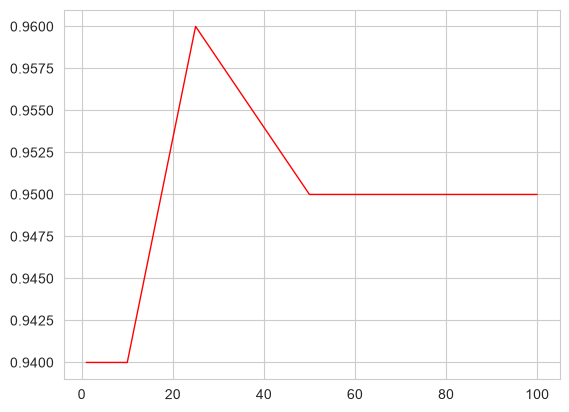

In [56]:
num_estimators = [1, 5, 10, 25, 50, 100]
f1 = [0.94, 0.94, 0.94, 0.96, 0.95, 0.95]

plt.plot(num_estimators, f1, color = 'red', linewidth = 1)

*Questions*

1. Initially, the F1 increases
2. No
3. From 50 estimators onwards
4. It takes longer and is more computationally expensive to use more estimators

**Task 11: Bagging with Different Base Models**

In [62]:
bag_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42
)

bag_tree.fit(
    X_train,
    y_train
)

y_pred_bagging = bag_tree.predict(
    X_test
)

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9385964912280702
F1: 0.9517241379310345


In [61]:
bag_logistic = BaggingClassifier(
    estimator=LogisticRegression(
        max_iter=1000
    ),
    n_estimators=100,
    random_state=42
)

bag_logistic.fit(
    X_train,
    y_train
)

y_pred_bagging = bag_logistic.predict(
    X_test
)

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

c:\Users\sophi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\sophi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://s

KeyboardInterrupt: 

In [60]:
bag_knn = BaggingClassifier(
    estimator=KNeighborsClassifier(),
    n_estimators=100,
    random_state=42
)

bag_knn.fit(
    X_train,
    y_train
)

y_pred_bagging = bag_knn.predict(
    X_test
)

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9122807017543859
F1: 0.9295774647887324


|Model| Accuracy    | F1 |
|-------| -------- | ------- |
|Bagged Decision Tree| 0.94  | 0.95    |
|Bagged Logistic Regression| N/A | N/A     |
|Bagged KNN| 0.91 | 0.93     |

*Questions*

1. Bagged decision tree
2. Yes
3. Bagged decision tree
4. It helps to standardize data with multiple different data samples

**Task 12: Build a Random Forest**

In [63]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [64]:
rf.fit(
    X_train,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [65]:
y_pred_rf = rf.predict(
    X_test
)

In [66]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf
)

print("Accuracy:", rf_accuracy)
print("F1:", rf_f1)

Accuracy: 0.956140350877193
F1: 0.9655172413793104


**Task 13: Bagging vs. Random Forest**

|Model| Accuracy    | F1 |
|-------| -------- | ------- |
|Decision Tree| 0.91  | 0.93    |
|Bagged Decision Trees| 0.94  | 0.95    |
|Random Forest| 0.96 | 0.97    |

*Questions*

1. They use multiple trees
2. Random feature selection
3. It helps use the entire range of data, not just a couple of features
4. The Random Forest model performed best
5. It will get trained on multiple different feature groups instead of just the same features over and over, reducing overfitting

Key Concept:
Random Forest = Bagged decision trees + random feature selection

**Task 14: MDI Feature Importance**

In [67]:
importance_mdi = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

print(importance_mdi)

worst area                 0.140016
worst concave points       0.129530
worst radius               0.097696
mean concave points        0.090885
worst perimeter            0.072226
mean perimeter             0.069574
mean radius                0.068676
mean concavity             0.057638
mean area                  0.049172
worst concavity            0.034340
area error                 0.033104
worst compactness          0.018600
worst texture              0.018597
radius error               0.016770
worst smoothness           0.012436
mean compactness           0.011715
perimeter error            0.009633
mean texture               0.009584
worst symmetry             0.008335
compactness error          0.005979
mean smoothness            0.005598
texture error              0.005214
worst fractal dimension    0.005166
mean symmetry              0.004666
mean fractal dimension     0.004489
fractal dimension error    0.004442
concavity error            0.004310
concave points error       0

In [68]:
importance_mdi.sum()

np.float64(1.0)

*Questions*

1. worst area
2. worst area, worst concave points, worst radius
3. smoothness error
4. The feature is pure
5. Splits show which features are more impure than others

**Task 15: Visualize MDI Feature Importance**

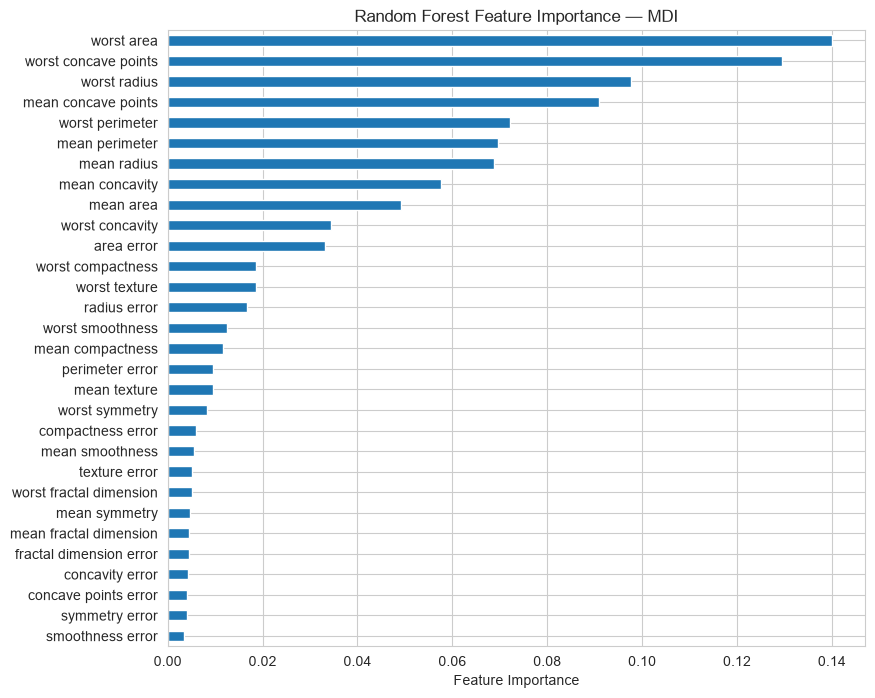

In [69]:
importance_mdi.sort_values().plot(
    kind="barh",
    figsize=(9, 8)
)

plt.xlabel(
    "Feature Importance"
)

plt.title(
    "Random Forest Feature Importance — MDI"
)

plt.show()

*Questions*

1. worst area, worst concave points, worst radius
2. Yes 
3. Yes
4. No, a feature with a low importance score can still be useful, just not as useful as a feature with a high importance

**Task 16**

*Question*

No, just because the worst radius feautre is the most important doesn't show what it means, just that it is helpful in making predictions. It is useful in predictions, and could just be associated with malignant tumors, not the cause of them.

**Task 17: Permutation Importance**

In [70]:
result = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42
)

In [71]:
importance_permutation = pd.Series(
    result.importances_mean,
    index=X_test.columns
).sort_values(
    ascending=False
)

print(importance_permutation)

compactness error          7.894737e-03
mean concave points        7.894737e-03
worst texture              7.017544e-03
worst area                 7.017544e-03
mean area                  5.263158e-03
mean smoothness            5.263158e-03
radius error               4.385965e-03
mean radius                4.385965e-03
concave points error       3.508772e-03
mean concavity             3.508772e-03
worst smoothness           2.631579e-03
worst concave points       2.631579e-03
mean fractal dimension     1.754386e-03
mean compactness           0.000000e+00
area error                 0.000000e+00
perimeter error            0.000000e+00
texture error              0.000000e+00
mean symmetry              0.000000e+00
mean perimeter             0.000000e+00
mean texture               0.000000e+00
concavity error            0.000000e+00
smoothness error           0.000000e+00
worst symmetry             0.000000e+00
fractal dimension error    0.000000e+00
symmetry error             0.000000e+00


*Questions*

1. compactness error
2. compactness error, mean concave points, worst texture
3. No
4. Most of the top MDI features became less important in the hightest permutation ranking
5. Yes

**Task 18: Visualize Permutation Importance**

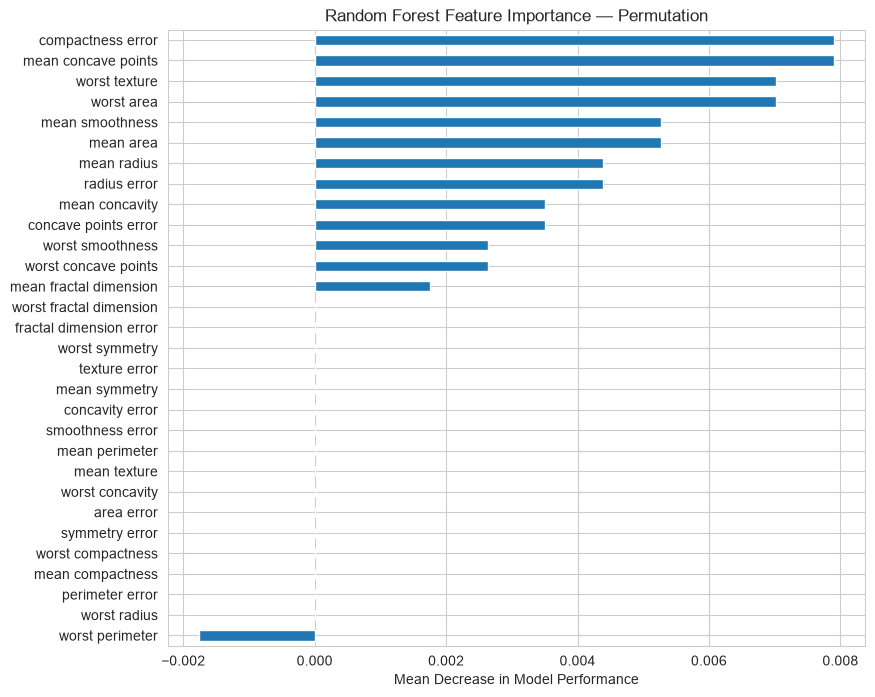

In [72]:
importance_permutation.sort_values().plot(
    kind="barh",
    figsize=(9, 8)
)

plt.xlabel(
    "Mean Decrease in Model Performance"
)

plt.title(
    "Random Forest Feature Importance — Permutation"
)

plt.show()

*Questions*

1. compactness error
2. mean fractal dimension, worst perimeter
3. A lot of features in this visualization have no importance whatsoever, whereas in the MDI visualization all features had at least some importance

**Task 19: Compare MDI and Permutation Importance**

In [73]:
importance_comparison = pd.DataFrame({
    "MDI": importance_mdi,
    "Permutation": importance_permutation
})

importance_comparison.sort_values(
    "MDI",
    ascending=False
)

,MDI,Permutation
worst area,0.140016,7.017544e-03
worst concave points,0.129530,2.631579e-03
worst radius,0.097696,-1.110223e-17
mean concave points,0.090885,7.894737e-03
worst perimeter,0.072226,-1.754386e-03
mean perimeter,0.069574,0.000000e+00
mean radius,0.068676,4.385965e-03
mean concavity,0.057638,3.508772e-03
mean area,0.049172,5.263158e-03
worst concavity,0.034340,0.000000e+00


|Question | Answer|
|-------| -------- |
|MDI is based on... |How much something appears|
|Permutation importance is based on... | The order in which something appears|
|MDI looks at... |Quantity|
|Permutation importance looks at... |Position|
|One limitation of MDI is... |How much something appears could relate to correlation, not causation|
|One advantage of permutation importance is... |It is better at sorting out features that are actually unimportant|

*Analysis*

1. worst area, worst concave points
2. Some features with different rankings are worst texture, compactness error, and mean smoothness
3. The are looking for different things to assign importance based off of
4. Permutation Importance
5. It works in terms of e, not simple decimal numbers

**Task 20: Investigate Correlated Features**

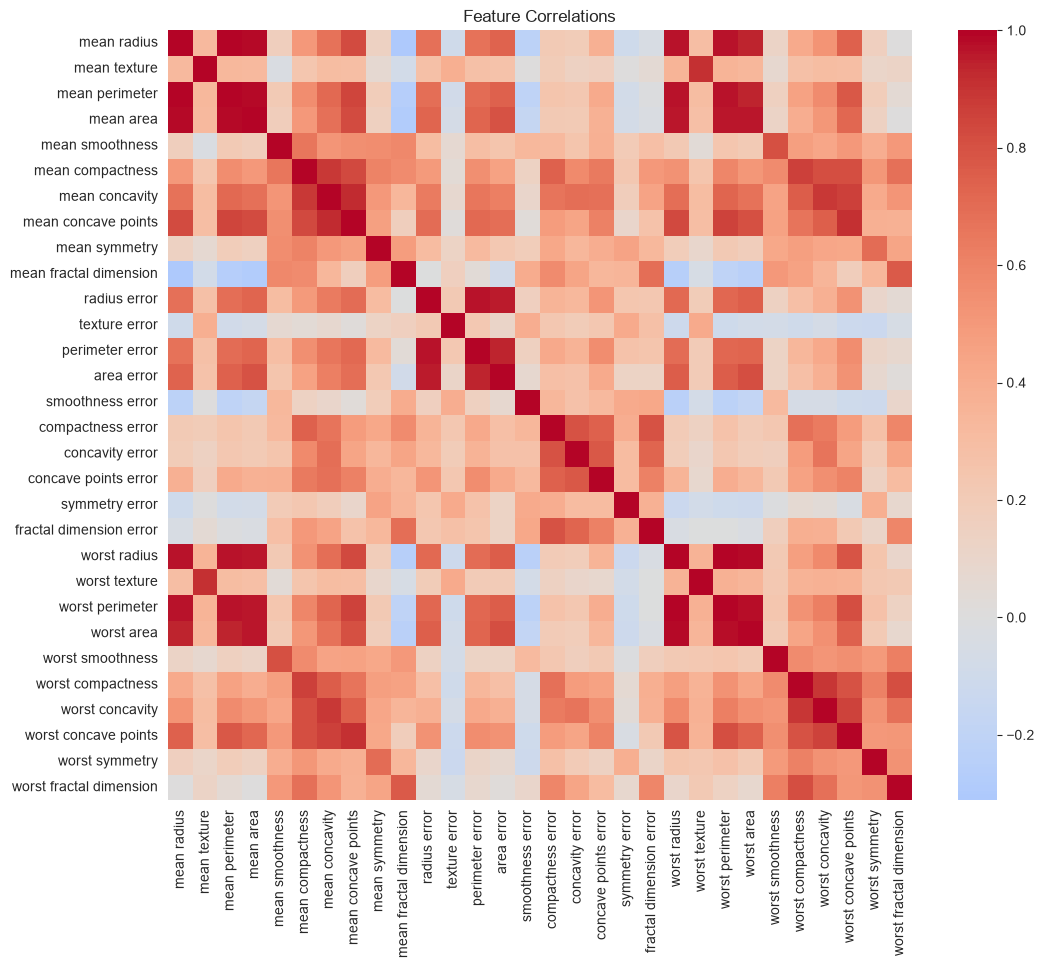

In [74]:
plt.figure(
    figsize=(12, 10)
)

sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0
)

plt.title(
    "Feature Correlations"
)

plt.show()

*Questions*

1. worst perimeter and worst area
2. If a lot of features are important and similar, it becomes hard to find out which features are actually imporant, and which just correlate with important features
3. Random feature selection
4. Yes because it could not show up that much
5. It is difficult to do

**Task 21: Build a Voting Classifier**

In [75]:
voting_model = VotingClassifier(
    estimators=[
        (
            "tree",
            DecisionTreeClassifier(
                random_state=42
            )
        ),
        (
            "logistic",
            LogisticRegression(
                max_iter=1000
            )
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ],
    voting="hard"
)

In [76]:
voting_model.fit(
    X_train,
    y_train
)

c:\Users\sophi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('tree', ...), ('logistic', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[DecisionTreeC...ndom_state=42), LogisticRegre...max_iter=1000), KNeighborsClassifier()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [77]:
y_pred_voting = voting_model.predict(
    X_test
)

In [79]:
accuracy = accuracy_score(
    y_test,
    y_pred_voting
)

print("Accuracy:", accuracy)

f1 = f1_score(
    y_test,
    y_pred_voting
)

print("F1:", f1)

Accuracy: 0.9473684210526315
F1: 0.9583333333333334


*Questions*

1. It looks at the majority of similar predictions across different models?
2. It looks at majority rather than randomness, and uses different models?
3. Almost
4. It helps get different predictions with different algorithms instead of the same algorithms on different groups of data

**Task 22: Final Model Comparison**

|Model| Accuracy    | F1 |
|-------| -------- | ------- |
|Random Forest| 0.96 | 0.97    |
|Voting Classifier|0.95|0.96|
|Bagged Decision Tree| 0.94  | 0.95    |
|Decision Tree| 0.91  | 0.93    |
|Bagged KNN| 0.91 | 0.93     |
|Bagged Logistic Regression| N/A | N/A     |

**Task 23: Final Analysis**

1. It creates different data sets to train on one type of model
2. Because datasets are created randomly, and the same feature may be randomly selected more than once
3. Because datasets are created randomly, and the same feature may not be selected at all
4. It needs to create datasets of identical sizes
5. Bootstrap Aggregating
6. It trains a separate model on each different sample from the bootstrap
7. It either has a majority vote of all the predictions, and the prediction with the highest number of appearances is selected (classification) or takes the average of the predictions and selects that (regression)
8. The different models used produce different predictions which are then averaged or voted, making variance lower by averaging many unstable models to reach a stable prediction
9. It takes many different predictions and uses them to create a stable prediction
10. It uses multiple decision trees instead of models
11. To make the trees less correlated, and use less features that could be nearly identical
12. It gets a wider range of data based on lots of different features as opposed to correlated features
13. Bagging uses separate models, Random Forest uses separate decision trees
14. Mean Decrease in Impurity
15. It measures how much model performance changes based on a single feature
16. Permutation importance is based on how much performance changes, whereas MDI is based on impurity
17. Importance could be distributed between features, throwing off how important they actually are
18. A feature's importance could be really high, but it could just appear that way, because other correlated features could be seen as less important because importance is split between them - the first feature could have nothing to do with causation
19. Random Forest
20. It performed better
21. Not always, sometimes it resulted in overfitting
22. Bagged Decision Tree
23. You get a more standardized prediction because you combine multiple models
24. There aren't any obvious drawbacks/disadvantages
25. No, because high accuracy could just be a sign of overfitting